# 41 — Stratification Index: Algorithm Walkthrough

This notebook explains **how the stratification index is calculated** in the
SIS Analysis pipeline, demonstrates each step on real data, and compares the
two formulations used across the project.

---
## Overview

| Variant | Formula | Used in |
|---|---|---|
| **Density Gradient** (Δρ / Δz) | `(ρ_bottom − ρ_surface) / (z_bottom − z_surface)` | `33_DO_PCA_corr.py`, `33_what_affects_do_v2.ipynb` |
| **Density Difference** (Δρ) | `ρ_bottom − ρ_surface` | `40a_PCA_env_corr_Tokyo_bay`, `40b_PCA_env_corr_Ise_bay` |

Both variants rely on **potential density anomaly σ₀** computed with the
[Gibbs SeaWater (GSW) Oceanographic Toolbox](https://www.teos-10.org/software.htm).


## 1. Imports & Data Loading

In [1]:
import pandas as pd
import numpy as np
import gsw
import matplotlib.pyplot as plt
import sys
from pathlib import Path

# Project utilities
project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths
from scripts.data_loader import load_and_process_data

import warnings
warnings.filterwarnings('ignore')


In [2]:
# Load the merged GeoDataFrame (feather cache)
merged_gdf = load_and_process_data(force_reload=False)
print(f"Total records: {len(merged_gdf):,}")
print(f"Columns available: {merged_gdf.columns.tolist()}")


Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...
Total records: 62,738
Columns available: ['uniqueid', 'zettaicode', 'locationna', 'wancode', 'prefectuei', 'watercode', 'renban', 'nendo', 'survey_ym', 'surveyyear', 'surveymont', 'surveyday', 'surveyhour', 'surveymini', 'saisuipoin', 'latitude', 'longitude', 'weather', 'cloud', 'fuko', 'fusoku', 'temp', 'color', 'saisuidept', 'depth', 'clearness', 'wtemp', 'ph', 'ph2', 'do_', 'do_2', 'salt', 'salt2', 'cod', 'cod2', 'rcod', 'rcod2', 'nh4n', 'nh4n2', 'no2n', 'no2n2', 'no3n', 'no3n2', 'tn', 'tn2', 'po4p', 'po4p2', 'tp', 'tp2', 'chlorophyl', 'chloroph_1', 'feiochin', 'feiochin2', 'toc', 'toc2', 'doc', 'doc2', 'dataflag', 'scale', 'geometry', 'year', 'watermass_name', 'division', 'details', 'season']


## 2. Understanding the `saisuipoin` Column

The `saisuipoin` column encodes the **sampling depth layer**:

| Code | Layer |
|------|-------|
| 1 | Surface |
| 2 | Bottom |

To calculate stratification we need **paired** surface and bottom
measurements at the same station and time.


In [3]:
# Check unique values
print("Unique saisuipoin values:", sorted(merged_gdf['saisuipoin'].dropna().unique()))

# Show counts per layer
print("\nRecord counts per layer:")
print(merged_gdf['saisuipoin'].value_counts().sort_index())


Unique saisuipoin values: [np.int64(1), np.int64(2)]

Record counts per layer:
saisuipoin
1    31371
2    31367
Name: count, dtype: int64


## 3. Building Layer-Specific Time-Series Matrices

The algorithm starts by creating station × year matrices for each
parameter, **separately for surface and bottom layers**.

The function `get_time_series_matrix()` performs these steps:
1. Filter by season (e.g. `'Summer'`).
2. Filter by `saisuipoin` code (1 = surface, 2 = bottom).
3. Convert the target parameter to numeric and drop NaNs.
4. Group by `(year, station)` and compute the annual mean.
5. Pivot to a **year × station** matrix.


In [4]:
def get_time_series_matrix(df, param, season_filter, saisuipoin=None):
    """Build a year × station matrix for a single parameter / layer."""
    mask = df['season'] == season_filter
    if saisuipoin is not None:
        mask &= df['saisuipoin'] == saisuipoin

    subset = df.loc[mask, ['surveyyear', 'zettaicode', param]].copy()
    subset[param] = pd.to_numeric(subset[param], errors='coerce')

    matrix = subset.groupby(['surveyyear', 'zettaicode'])[param].mean().unstack()
    matrix.index = matrix.index.astype(int)
    matrix.index.name = 'year'
    return matrix

# Build the four matrices needed for density
sst_matrix = get_time_series_matrix(merged_gdf, 'wtemp', 'Summer', saisuipoin=1)
sbt_matrix = get_time_series_matrix(merged_gdf, 'wtemp', 'Summer', saisuipoin=2)
sss_matrix = get_time_series_matrix(merged_gdf, 'salt2', 'Summer', saisuipoin=1)
sbs_matrix = get_time_series_matrix(merged_gdf, 'salt2', 'Summer', saisuipoin=2)

# Depth matrices (needed for the gradient variant)
surface_depth_matrix = get_time_series_matrix(merged_gdf, 'saisuidept', 'Summer', saisuipoin=1)
bottom_depth_matrix  = get_time_series_matrix(merged_gdf, 'saisuidept', 'Summer', saisuipoin=2)

print(f"SST matrix shape (year × station): {sst_matrix.shape}")
print(f"SBT matrix shape (year × station): {sbt_matrix.shape}")
print(f"SSS matrix shape (year × station): {sss_matrix.shape}")
print(f"SBS matrix shape (year × station): {sbs_matrix.shape}")
print(f"Surface depth matrix shape: {surface_depth_matrix.shape}")
print(f"Bottom  depth matrix shape: {bottom_depth_matrix.shape}")


SST matrix shape (year × station): (43, 188)
SBT matrix shape (year × station): (43, 188)
SSS matrix shape (year × station): (43, 188)
SBS matrix shape (year × station): (43, 188)
Surface depth matrix shape: (43, 188)
Bottom  depth matrix shape: (43, 188)


## 4. Computing Potential Density Anomaly (σ₀)

The GSW toolbox converts in-situ measurements to physically meaningful
quantities through three steps:

### Step-by-step

1. **Practical Salinity → Absolute Salinity**
   ```
   SA = gsw.SA_from_SP(SP, p, lon, lat)
   ```
   Converts Practical Salinity (PSU) to Absolute Salinity (g/kg),
   accounting for the spatial variation of seawater composition.

2. **In-situ Temperature → Conservative Temperature**
   ```
   CT = gsw.CT_from_t(SA, t, p)
   ```
   Converts the measured in-situ temperature to Conservative Temperature,
   which is a more accurate measure of heat content.

3. **Potential Density Anomaly σ₀**
   ```
   sigma0 = gsw.sigma0(SA, CT)
   ```
   Computes σ₀ = ρ(SA, CT, 0 dbar) − 1000 kg/m³ .
   This is the density the parcel would have if brought adiabatically
   to the sea surface (reference pressure = 0 dbar).

> **Note:** In our pipeline the sea-surface pressure `p = 0` is used for
> both layers. This is intentional: σ₀ removes the effect of pressure so
> that we compare water masses on equal footing.


In [5]:
def compute_density_matrix(temp_matrix, salt_matrix, station_coords):
    """
    Compute σ₀ (potential density anomaly) for every (year, station) cell.

    Parameters
    ----------
    temp_matrix  : DataFrame, year × station  — in-situ temperature (°C)
    salt_matrix  : DataFrame, year × station  — practical salinity (PSU)
    station_coords : DataFrame indexed by zettaicode with 'latitude', 'longitude'

    Returns
    -------
    density_matrix : DataFrame, year × station  — σ₀ values (kg/m³)
    """
    density_matrix = pd.DataFrame(
        index=temp_matrix.index,
        columns=temp_matrix.columns,
        dtype=float,
    )
    common_stations = (
        temp_matrix.columns
        .intersection(salt_matrix.columns)
        .intersection(station_coords.index)
    )

    for stn in common_stations:
        lat = station_coords.loc[stn, 'latitude']
        lon = station_coords.loc[stn, 'longitude']

        t = temp_matrix[stn]
        s = salt_matrix[stn]

        valid = t.notna() & s.notna()
        if valid.sum() == 0:
            continue

        # GSW conversions
        SA = gsw.SA_from_SP(s[valid], 0, lon, lat)   # Absolute Salinity
        CT = gsw.CT_from_t(SA, t[valid], 0)           # Conservative Temp
        sigma0 = gsw.sigma0(SA, CT)                    # σ₀

        density_matrix.loc[valid, stn] = sigma0.values

    density_matrix.index.name = 'year'
    return density_matrix.astype(float)

# Station coordinates lookup
stations = (
    merged_gdf[['zettaicode', 'latitude', 'longitude']]
    .drop_duplicates('zettaicode')
    .set_index('zettaicode')
)

# Compute surface and bottom density matrices
surface_density = compute_density_matrix(sst_matrix, sss_matrix, stations)
bottom_density  = compute_density_matrix(sbt_matrix, sbs_matrix, stations)

print(f"Surface density matrix: {surface_density.shape} — non-NaN cells: {surface_density.notna().sum().sum()}")
print(f"Bottom  density matrix: {bottom_density.shape}  — non-NaN cells: {bottom_density.notna().sum().sum()}")


Surface density matrix: (43, 188) — non-NaN cells: 7899
Bottom  density matrix: (43, 188)  — non-NaN cells: 7890


## 5. Stratification Calculation — Two Variants

### 5a. Density Gradient (Δρ / Δz)

Used in `33_DO_PCA_corr.py` and `33_what_affects_do_v2.ipynb`.

$$
\text{Stratification Index} = \frac{\sigma_{0,\text{bottom}} - \sigma_{0,\text{surface}}}{z_{\text{bottom}} - z_{\text{surface}}}
$$

This normalises by the depth interval, giving units of **kg m⁻³ per metre**.
It is more physically meaningful when stations have very different water
depths, because a given density difference across a 5 m column implies much
stronger stability than the same difference across 50 m.

### 5b. Density Difference (Δρ)

Used in `40a_PCA_env_corr_Tokyo_bay` and `40b_PCA_env_corr_Ise_bay`.

$$
\text{Stratification} = \sigma_{0,\text{bottom}} - \sigma_{0,\text{surface}}
$$

A simpler proxy (units: **kg m⁻³**) that ignores the depth span.
Positive values → heavier water at the bottom → stable stratification.


In [6]:
# ── Variant A: Density Gradient  ──────────────────────────────────────
depth_diff = bottom_depth_matrix - surface_depth_matrix
depth_diff = depth_diff.replace(0, np.nan)        # avoid division by zero

stratification_gradient = (bottom_density - surface_density) / depth_diff

print("=== Variant A: Density Gradient (Δρ / Δz) ===")
print(f"Shape: {stratification_gradient.shape}")
print(f"Non-NaN cells: {stratification_gradient.notna().sum().sum()}")
print(f"Mean : {stratification_gradient.stack().mean():.4f} kg/m³/m")
print(f"Median: {stratification_gradient.stack().median():.4f} kg/m³/m")
print()

# ── Variant B: Density Difference ─────────────────────────────────────
common_stns = surface_density.columns.intersection(bottom_density.columns)
stratification_diff = bottom_density[common_stns] - surface_density[common_stns]

print("=== Variant B: Density Difference (Δρ) ===")
print(f"Shape: {stratification_diff.shape}")
print(f"Non-NaN cells: {stratification_diff.notna().sum().sum()}")
print(f"Mean : {stratification_diff.stack().mean():.4f} kg/m³")
print(f"Median: {stratification_diff.stack().median():.4f} kg/m³")


=== Variant A: Density Gradient (Δρ / Δz) ===
Shape: (43, 188)
Non-NaN cells: 7629
Mean : 0.2551 kg/m³/m
Median: 0.0925 kg/m³/m

=== Variant B: Density Difference (Δρ) ===
Shape: (43, 188)
Non-NaN cells: 7890
Mean : 3.2520 kg/m³
Median: 1.8249 kg/m³


## 6. Worked Example — Single Station

Let's trace the full calculation for **one station in one year** so every
intermediate value is visible.


In [7]:
# Pick a station with valid surface & bottom data
common_stns_list = list(
    sst_matrix.columns
    .intersection(sbt_matrix.columns)
    .intersection(sss_matrix.columns)
    .intersection(sbs_matrix.columns)
    .intersection(surface_depth_matrix.columns)
    .intersection(bottom_depth_matrix.columns)
    .intersection(stations.index)
)

# Find a station-year pair with all six values present
example_stn = None
example_year = None
for stn in common_stns_list:
    for yr in sst_matrix.index:
        vals = [
            sst_matrix.loc[yr, stn] if stn in sst_matrix.columns else np.nan,
            sbt_matrix.loc[yr, stn] if stn in sbt_matrix.columns else np.nan,
            sss_matrix.loc[yr, stn] if stn in sss_matrix.columns else np.nan,
            sbs_matrix.loc[yr, stn] if stn in sbs_matrix.columns else np.nan,
            surface_depth_matrix.loc[yr, stn] if stn in surface_depth_matrix.columns else np.nan,
            bottom_depth_matrix.loc[yr, stn] if stn in bottom_depth_matrix.columns else np.nan,
        ]
        if all(pd.notna(v) for v in vals):
            example_stn = stn
            example_year = yr
            break
    if example_stn is not None:
        break

print(f"Example station: {example_stn}")
print(f"Example year   : {example_year}")
print()

# Raw measurements
t_surf = sst_matrix.loc[example_year, example_stn]
t_bot  = sbt_matrix.loc[example_year, example_stn]
s_surf = sss_matrix.loc[example_year, example_stn]
s_bot  = sbs_matrix.loc[example_year, example_stn]
z_surf = surface_depth_matrix.loc[example_year, example_stn]
z_bot  = bottom_depth_matrix.loc[example_year, example_stn]
lat = stations.loc[example_stn, 'latitude']
lon = stations.loc[example_stn, 'longitude']

print(f"Latitude : {lat:.4f}°N")
print(f"Longitude: {lon:.4f}°E")
print()
print(f"Surface temperature (wtemp) : {t_surf:.2f} °C")
print(f"Bottom  temperature (wtemp) : {t_bot:.2f} °C")
print(f"Surface salinity   (salt2)  : {s_surf:.2f} PSU")
print(f"Bottom  salinity   (salt2)  : {s_bot:.2f} PSU")
print(f"Surface depth  (saisuidept) : {z_surf:.1f} m")
print(f"Bottom  depth  (saisuidept) : {z_bot:.1f} m")


Example station: 00000122
Example year   : 1981

Latitude : 35.6472°N
Longitude: 139.9900°E

Surface temperature (wtemp) : 29.00 °C
Bottom  temperature (wtemp) : 29.00 °C
Surface salinity   (salt2)  : 26.23 PSU
Bottom  salinity   (salt2)  : 26.29 PSU
Surface depth  (saisuidept) : 0.5 m
Bottom  depth  (saisuidept) : 5.0 m


In [8]:
# ── Step-by-step GSW conversion ───────────────────────────────────────
# Surface
SA_surf = gsw.SA_from_SP(s_surf, 0, lon, lat)
CT_surf = gsw.CT_from_t(SA_surf, t_surf, 0)
sig0_surf = gsw.sigma0(SA_surf, CT_surf)

# Bottom
SA_bot = gsw.SA_from_SP(s_bot, 0, lon, lat)
CT_bot = gsw.CT_from_t(SA_bot, t_bot, 0)
sig0_bot = gsw.sigma0(SA_bot, CT_bot)

print("─── GSW Conversion Results ───")
print(f"Surface: SA = {SA_surf:.4f} g/kg,  CT = {CT_surf:.4f} °C,  σ₀ = {sig0_surf:.4f} kg/m³")
print(f"Bottom : SA = {SA_bot:.4f} g/kg,  CT = {CT_bot:.4f} °C,  σ₀ = {sig0_bot:.4f} kg/m³")
print()

# Stratification
delta_rho = sig0_bot - sig0_surf
delta_z   = z_bot - z_surf
strat_gradient = delta_rho / delta_z if delta_z != 0 else np.nan

print("─── Stratification ───")
print(f"Δρ  = σ₀_bot − σ₀_surf = {delta_rho:.4f} kg/m³   (Variant B: Density Difference)")
print(f"Δz  = z_bot  − z_surf  = {delta_z:.1f} m")
print(f"Δρ/Δz = {strat_gradient:.6f} kg/m³/m   (Variant A: Density Gradient)")
print()
if delta_rho > 0:
    print("→ Positive Δρ: bottom water is denser than surface → STABLE stratification.")
elif delta_rho < 0:
    print("→ Negative Δρ: surface water is denser → UNSTABLE (convective) conditions.")
else:
    print("→ Δρ ≈ 0: water column is well-mixed (no stratification).")


─── GSW Conversion Results ───
Surface: SA = 26.3542 g/kg,  CT = 29.3783 °C,  σ₀ = 15.4959 kg/m³
Bottom : SA = 26.4144 g/kg,  CT = 29.3758 °C,  σ₀ = 15.5407 kg/m³

─── Stratification ───
Δρ  = σ₀_bot − σ₀_surf = 0.0448 kg/m³   (Variant B: Density Difference)
Δz  = z_bot  − z_surf  = 4.5 m
Δρ/Δz = 0.009967 kg/m³/m   (Variant A: Density Gradient)

→ Positive Δρ: bottom water is denser than surface → STABLE stratification.


## 7. Visualisations

### 7a. Distribution of Stratification Values


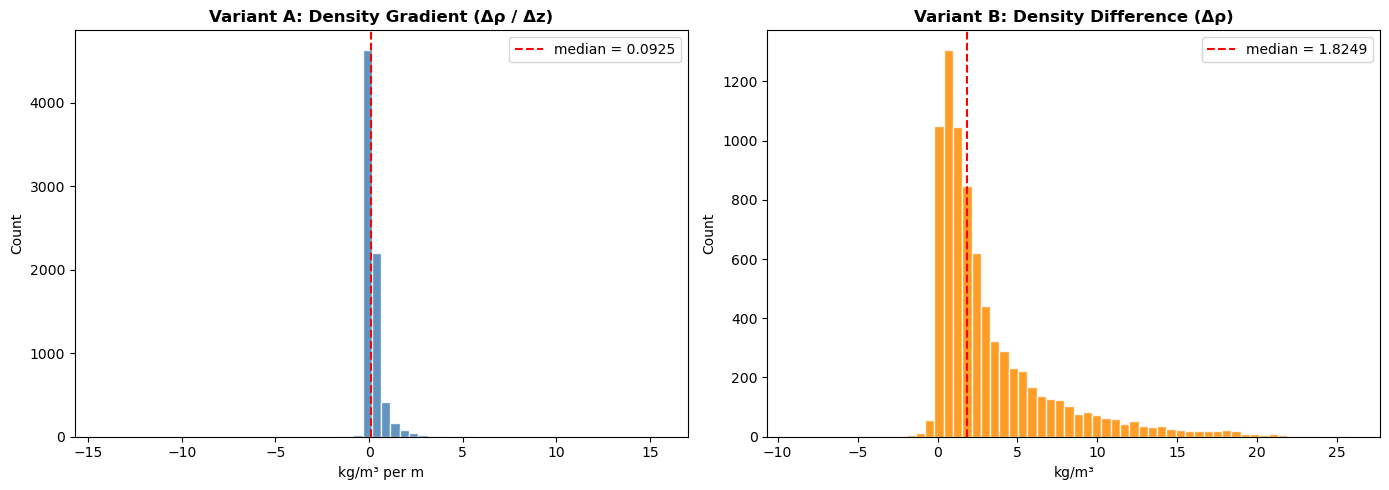

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Variant A
vals_a = stratification_gradient.stack().dropna()
axes[0].hist(vals_a, bins=60, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(vals_a.median(), color='red', linestyle='--', label=f'median = {vals_a.median():.4f}')
axes[0].set_title('Variant A: Density Gradient (Δρ / Δz)', fontweight='bold')
axes[0].set_xlabel('kg/m³ per m')
axes[0].set_ylabel('Count')
axes[0].legend()

# Variant B
vals_b = stratification_diff.stack().dropna()
axes[1].hist(vals_b, bins=60, color='darkorange', edgecolor='white', alpha=0.85)
axes[1].axvline(vals_b.median(), color='red', linestyle='--', label=f'median = {vals_b.median():.4f}')
axes[1].set_title('Variant B: Density Difference (Δρ)', fontweight='bold')
axes[1].set_xlabel('kg/m³')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.show()


### 7b. Annual Mean Stratification Time-Series


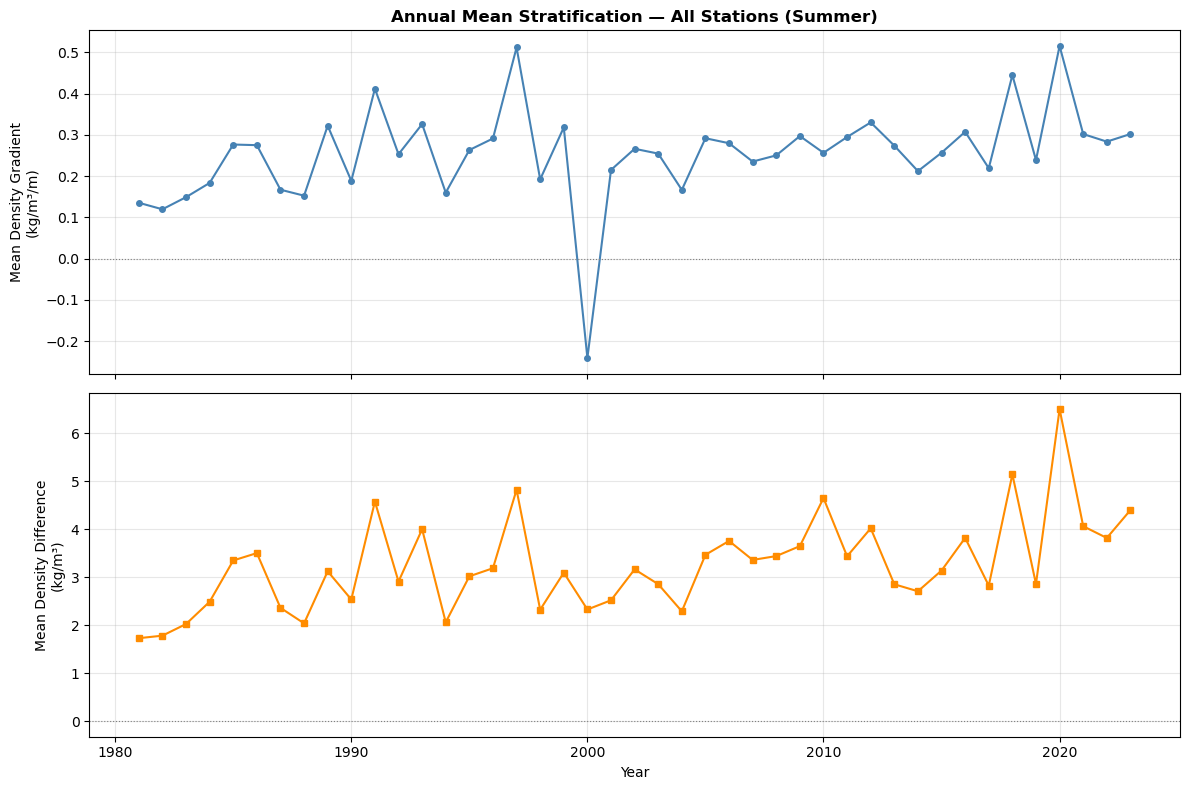

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Variant A — annual mean across all stations
annual_a = stratification_gradient.mean(axis=1).dropna()
axes[0].plot(annual_a.index, annual_a.values, 'o-', color='steelblue', markersize=4)
axes[0].set_ylabel('Mean Density Gradient\n(kg/m³/m)')
axes[0].set_title('Annual Mean Stratification — All Stations (Summer)', fontweight='bold')
axes[0].axhline(0, color='gray', linestyle=':', linewidth=0.8)
axes[0].grid(alpha=0.3)

# Variant B
annual_b = stratification_diff.mean(axis=1).dropna()
axes[1].plot(annual_b.index, annual_b.values, 's-', color='darkorange', markersize=4)
axes[1].set_ylabel('Mean Density Difference\n(kg/m³)')
axes[1].set_xlabel('Year')
axes[1].axhline(0, color='gray', linestyle=':', linewidth=0.8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 7c. Comparison of the Two Variants (scatter)


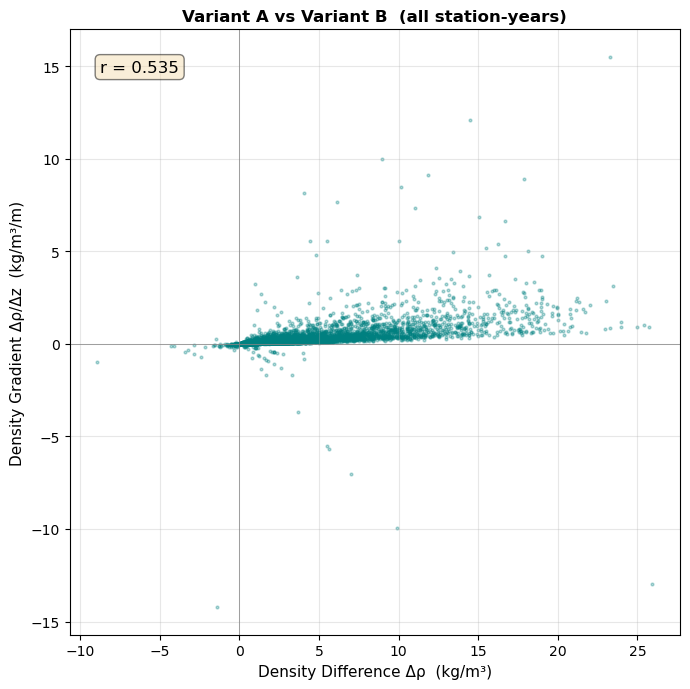

In [11]:
# Flatten both variants to matching (year, station) pairs
flat_a = stratification_gradient.stack().rename('gradient')
flat_b = stratification_diff.stack().rename('diff')
comparison = pd.concat([flat_a, flat_b], axis=1).dropna()

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(comparison['diff'], comparison['gradient'], s=4, alpha=0.3, color='teal')
ax.set_xlabel('Density Difference Δρ  (kg/m³)', fontsize=11)
ax.set_ylabel('Density Gradient Δρ/Δz  (kg/m³/m)', fontsize=11)
ax.set_title('Variant A vs Variant B  (all station-years)', fontweight='bold')
ax.axhline(0, color='gray', linewidth=0.5)
ax.axvline(0, color='gray', linewidth=0.5)
ax.grid(alpha=0.3)

r = comparison['diff'].corr(comparison['gradient'])
ax.text(0.05, 0.95, f'r = {r:.3f}', transform=ax.transAxes,
        fontsize=12, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
plt.tight_layout()
plt.show()


## 8. Summary

| Aspect | Variant A (Density Gradient) | Variant B (Density Difference) |
|---|---|---|
| **Formula** | (σ₀_bot − σ₀_surf) / (z_bot − z_surf) | σ₀_bot − σ₀_surf |
| **Units** | kg m⁻³ m⁻¹ | kg m⁻³ |
| **Normalised by depth?** | ✅ Yes | ❌ No |
| **Sensitive to bathymetry** | Less so (depth-normalised) | More so |
| **Scripts using it** | `33_DO_PCA_corr.py` | `40a/b_PCA_env_corr_*.py` |

**Key takeaways:**
- Both variants use σ₀ from the GSW toolbox → physically consistent.
- Variant A is preferred when comparing stations with **different water depths**.
- Variant B is simpler and sufficient when stations share similar depths
  (e.g. within a single bay).
- Positive values always indicate **stable** stratification (denser water below).
